# Notebook 03 · Limpieza y tratamiento de datos
**Proyecto:** desnutrición crónica infantil con ENDES 2025 y XGBoost · IS-484 · UNSCH

Aquí se **limpia** el dataset que en el notebook 02 se analizó en crudo. El resultado se guarda en un archivo **nuevo** (`dataset_limpio.csv`); el crudo (`dataset_integrado_crudo.csv`) **no se toca** y queda disponible para seguir analizándolo (al final se comprueba que no cambió).

### Orden de trabajo
| Paso | Qué se hace | Por qué |
|---|---|---|
| 1 | Quitar niños sin objetivo | No se puede entrenar sin la respuesta |
| 2 | Revisar duplicados | Evitar dar doble peso a un mismo caso |
| 3 | Códigos especiales → `NaN` y recodificaciones | Un "9998" no es un peso |
| 4 | Reglas lógicas | Corregir lo imposible |
| 5 | Valores atípicos (RIC) | Decidir qué extremos son reales |
| 6 | Vacunas según la edad | "Aún no corresponde" no es "no vacunado" |
| 7 | Codificar binarias, ordinales y nominales | Que cada número signifique lo que parece |
| 8 | Diagnóstico de vacíos | Entender por qué faltan |
| 9 | División train/test por conglomerado | Antes de calcular cualquier estadístico |
| 10 | Imputación y escalado (solo con *train*) | Evitar fuga de datos |
| 11 | Verificación y guardado | Comprobar que todo quedó bien |
| 12 | Efecto de la limpieza en los modelos | Medir cuánto mejoró |

## 0. Antes de empezar: cómo leer los gráficos
Los gráficos de este notebook son de dos tipos. Aquí se muestra cada uno con una explicación.

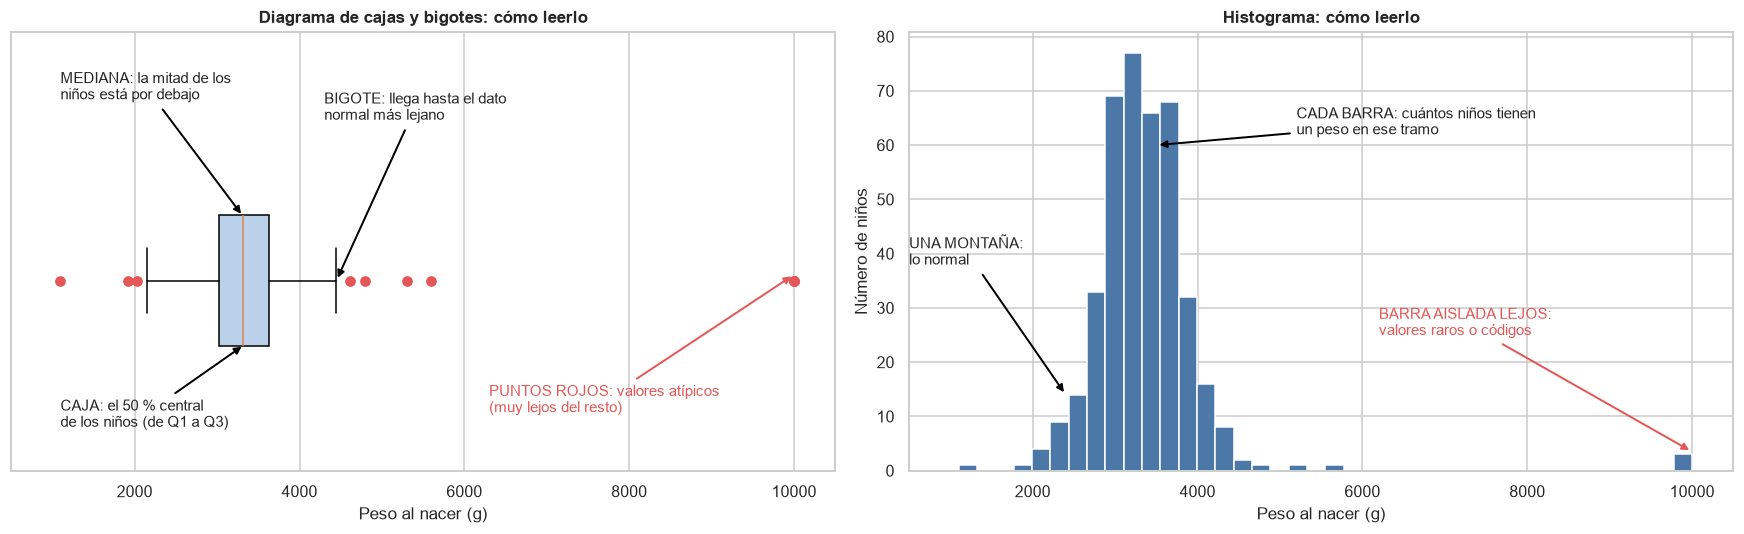

In [1]:
import hashlib
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
AZUL, NARANJA, ROJO, GRIS, VERDE = "#4C78A8", "#F58518", "#E45756", "#9D9D9D", "#54A24B"


def nota(texto):
    display(Markdown(texto))


# ---- Guía visual: caja con bigotes e histograma, con datos inventados
rng = np.random.default_rng(3)
ejemplo = np.concatenate([rng.normal(3300, 450, 400), [5300, 5600, 1100, 9998, 9998, 9998]])
q1, med, q3 = np.percentile(ejemplo, [25, 50, 75])
tope = q3 + 1.5 * (q3 - q1)
bigote_der = ejemplo[ejemplo <= tope].max()
flecha = {"arrowstyle": "-|>", "color": "black", "lw": 1.3}
flecha_roja = {"arrowstyle": "-|>", "color": ROJO, "lw": 1.3}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.boxplot(ejemplo, vert=False, widths=0.45, patch_artist=True, boxprops={"facecolor": "#BBD1EA"},
           flierprops={"markerfacecolor": ROJO, "markeredgecolor": ROJO, "markersize": 6})
ax.annotate("MEDIANA: la mitad de los\nniños está por debajo", xy=(med, 1.22), xytext=(1100, 1.62), arrowprops=flecha, fontsize=9.5)
ax.annotate("CAJA: el 50 % central\nde los niños (de Q1 a Q3)", xy=((q1 + q3) / 2, 0.78), xytext=(1100, 0.5), arrowprops=flecha, fontsize=9.5)
ax.annotate("BIGOTE: llega hasta el dato\nnormal más lejano", xy=(bigote_der, 1.0), xytext=(4300, 1.55), arrowprops=flecha, fontsize=9.5)
ax.annotate("PUNTOS ROJOS: valores atípicos\n(muy lejos del resto)", xy=(9998, 1.02), xytext=(6300, 0.55), arrowprops=flecha_roja, fontsize=9.5, color=ROJO)
ax.set_yticks([])
ax.set_xlabel("Peso al nacer (g)")
ax.set_title("Diagrama de cajas y bigotes: cómo leerlo")
ax.set_ylim(0.35, 1.85)
ax.set_xlim(500, 10500)

ax = axes[1]
ax.hist(ejemplo, bins=40, color=AZUL)
ax.annotate("CADA BARRA: cuántos niños tienen\nun peso en ese tramo", xy=(3500, 60), xytext=(5200, 62), arrowprops=flecha, fontsize=9.5)
ax.annotate("BARRA AISLADA LEJOS:\nvalores raros o códigos", xy=(9998, 3.5), xytext=(6200, 25), arrowprops=flecha_roja, fontsize=9.5, color=ROJO)
ax.annotate("UNA MONTAÑA:\nlo normal", xy=(2400, 14), xytext=(500, 38), arrowprops=flecha, fontsize=9.5)
ax.set_xlabel("Peso al nacer (g)")
ax.set_ylabel("Número de niños")
ax.set_title("Histograma: cómo leerlo")
ax.set_xlim(500, 10500)
plt.tight_layout()
plt.show()

**Regla rápida:** en una caja, cuanto más **corta** y **centrada** esté, más parecidos son los datos entre sí; los **puntos rojos** son los casos raros. En un histograma se busca **una sola montaña**: una barra suelta a lo lejos casi siempre es un código o un error.

## 1. Carga del dataset crudo y registro de cambios
Se lee el crudo, se calcula su "huella" (para comprobar al final que no se modificó) y se trabaja sobre una **copia**. Cada paso queda anotado en un registro.

In [2]:
RAIZ = Path.cwd().parent if Path.cwd().name == "2 notebooks" else Path.cwd()
SALIDA = RAIZ / "3 datos_procesados"
RUTA_CRUDO = SALIDA / "dataset_integrado_crudo.csv"
HUELLA_CRUDO = hashlib.md5(RUTA_CRUDO.read_bytes()).hexdigest()

crudo = pd.read_csv(RUTA_CRUDO, dtype={"caseid": str, "hhid": str})
dic = pd.read_csv(SALIDA / "diccionario_variables.csv")
df = crudo.copy()                                    # <- todo el trabajo se hace sobre esta copia

FEATURES = dic.loc[dic.rol == "feature", "nombre"].tolist()
CATEG = dic.loc[(dic.rol == "feature") & (dic.tipo == "categórica"), "nombre"].tolist()
CODIGOS = {r.nombre: [int(float(x)) for x in str(r.codigos_a_nan).split(",") if x.strip()]
           for r in dic.itertuples() if isinstance(r.codigos_a_nan, str) and r.codigos_a_nan.strip()}

LOG = []


def registrar(paso, accion, valores):
    LOG.append({"paso": paso, "acción": accion, "afectados": int(valores), "filas": len(df), "columnas": df.shape[1]})


print(f"Crudo: {crudo.shape[0]:,} niños × {crudo.shape[1]} columnas | huella: {HUELLA_CRUDO[:10]}…")

Crudo: 18,841 niños × 50 columnas | huella: 0f7da73318…


## Paso 1 · Quitar los niños sin objetivo
818 niños no tienen un puntaje Z válido (no se les midió la talla o el dato se marcó como inválido). Sin la respuesta no sirven para entrenar ni para evaluar, así que se eliminan.

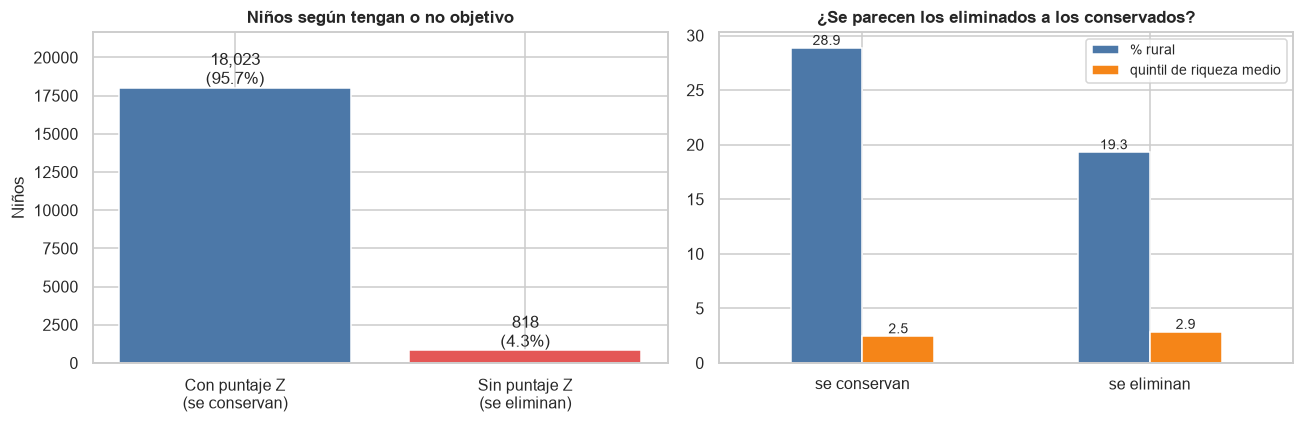

**Cómo leerlo:** izquierda, cuántos niños se quedan y cuántos salen; derecha, si los que salen son distintos de los que se quedan.  
**Qué vemos:** salen 818 niños (4.3 %). Eran algo más urbanos y de mayor nivel de riqueza (19 % rural frente a 29 %), lo que sugiere que son niños a los que no se pudo medir. Es una pérdida pequeña, pero conviene recordarla al interpretar resultados. Quedan **18,023** niños y ninguno tiene la edad vacía.

In [3]:
sin_obj = df[df["haz"].isna()]
con_obj = df[df["haz"].notna()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.bar(["Con puntaje Z\n(se conservan)", "Sin puntaje Z\n(se eliminan)"], [len(con_obj), len(sin_obj)], color=[AZUL, ROJO])
for i, v in enumerate([len(con_obj), len(sin_obj)]):
    ax.text(i, v + 250, f"{v:,}\n({100 * v / len(df):.1f}%)", ha="center")
ax.set_ylim(0, len(df) * 1.15)
ax.set_ylabel("Niños")
ax.set_title("Niños según tengan o no objetivo")

comp = pd.DataFrame({
    "% rural": [(con_obj.area_residencia == 2).mean() * 100, (sin_obj.area_residencia == 2).mean() * 100],
    "quintil de riqueza medio": [con_obj.quintil_riqueza.mean(), sin_obj.quintil_riqueza.mean()],
}, index=["se conservan", "se eliminan"])
comp.plot.bar(ax=axes[1], rot=0, color=[AZUL, NARANJA])
axes[1].set_title("¿Se parecen los eliminados a los conservados?")
axes[1].legend(fontsize=9)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f", fontsize=9)
plt.tight_layout()
plt.show()

df = df[df["haz"].notna()].reset_index(drop=True)
registrar("1", "Eliminar niños sin puntaje Z válido", len(sin_obj))
nota(f"**Cómo leerlo:** izquierda, cuántos niños se quedan y cuántos salen; derecha, si los que salen son distintos de los que se quedan.  \n"
     f"**Qué vemos:** salen {len(sin_obj)} niños ({100 * len(sin_obj) / len(crudo):.1f} %). Eran algo más urbanos y de mayor nivel de riqueza "
     f"({comp.iloc[1, 0]:.0f} % rural frente a {comp.iloc[0, 0]:.0f} %), lo que sugiere que son niños a los que no se pudo medir. "
     f"Es una pérdida pequeña, pero conviene recordarla al interpretar resultados. Quedan **{len(df):,}** niños y ninguno tiene la edad vacía.")

## Paso 2 · Duplicados

In [4]:
dup_filas = int(df.duplicated().sum())
dup_features = int(df.duplicated(FEATURES).sum())
madres = df["caseid"].nunique()
registrar("2", "Eliminar duplicados exactos", dup_filas)
nota(f"**Resultado:** {dup_filas} filas duplicadas y {dup_features} niños con las 42 variables idénticas: **no hay nada que eliminar**.  \n"
     f"Lo que sí existe son hermanos: hay {madres:,} madres para {len(df):,} niños. No son duplicados (cada niño tiene su propio peso, edad y talla), pero comparten madre, hogar y conglomerado, "
     f"por eso más adelante la división train/test se hace **por conglomerado**.")

**Resultado:** 0 filas duplicadas y 0 niños con las 42 variables idénticas: **no hay nada que eliminar**.  
Lo que sí existe son hermanos: hay 16,317 madres para 18,023 niños. No son duplicados (cada niño tiene su propio peso, edad y talla), pero comparten madre, hogar y conglomerado, por eso más adelante la división train/test se hace **por conglomerado**.

## Paso 3 · Códigos especiales → `NaN`
Los "no sabe", "no se pesó" o "no se pudo medir" vienen como números (9996, 9998, 9999, 98, 8, 9). Se convierten en `NaN` **variable por variable**, con la lista del diccionario.

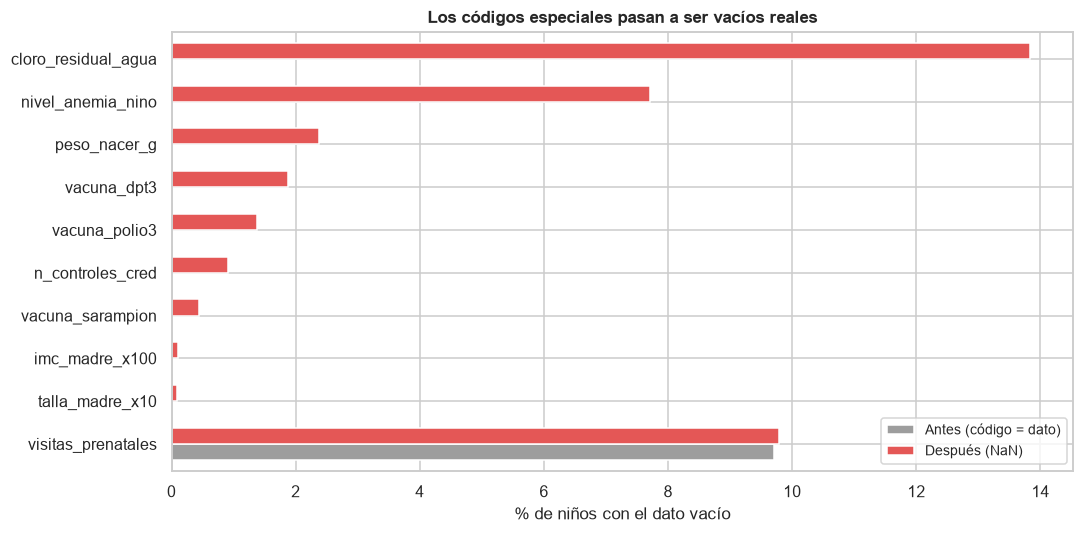

**Cómo leerlo:** barra gris = % de vacíos *antes* (los códigos contaban como datos, así que casi no había vacíos); barra roja = % de vacíos *después*.  
**Qué vemos:** se convirtieron 5,237 valores en 20 variables. Las más afectadas: `cloro_residual_agua` (2,494) y `nivel_anemia_nino` (1,388). No se inventa ningún dato: solo se reconoce que **no se sabe**.

In [5]:
conv = {}
for var, cods in CODIGOS.items():
    conv[var] = int(df[var].isin(cods).sum())
    df[var] = df[var].replace(cods, np.nan)
conv = pd.Series(conv)
conv = conv[conv > 0].sort_values(ascending=False)
registrar("3", "Códigos especiales (9996-9999, 98, 9, 8) a NaN", conv.sum())

base = crudo[crudo["haz"].notna()].reset_index(drop=True)          # crudo filtrado, para comparar
top = conv.head(10).index
comp = pd.DataFrame({"Antes (código = dato)": [base[v].isna().mean() * 100 for v in top],
                     "Después (NaN)": [df[v].isna().mean() * 100 for v in top]}, index=top)

fig, ax = plt.subplots(figsize=(10, 5))
comp[::-1].plot.barh(ax=ax, color=[GRIS, ROJO], width=0.75)
ax.set_xlabel("% de niños con el dato vacío")
ax.set_title("Los códigos especiales pasan a ser vacíos reales")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
nota(f"**Cómo leerlo:** barra gris = % de vacíos *antes* (los códigos contaban como datos, así que casi no había vacíos); barra roja = % de vacíos *después*.  \n"
     f"**Qué vemos:** se convirtieron {int(conv.sum()):,} valores en {len(conv)} variables. Las más afectadas: `{conv.index[0]}` ({conv.iloc[0]:,}) y `nivel_anemia_nino` ({conv.get('nivel_anemia_nino', 0):,}). "
     f"No se inventa ningún dato: solo se reconoce que **no se sabe**.")

### Efecto sobre las variables numéricas
Cajas e histogramas de las variables con códigos, **antes** (rojo) y **después** (azul).

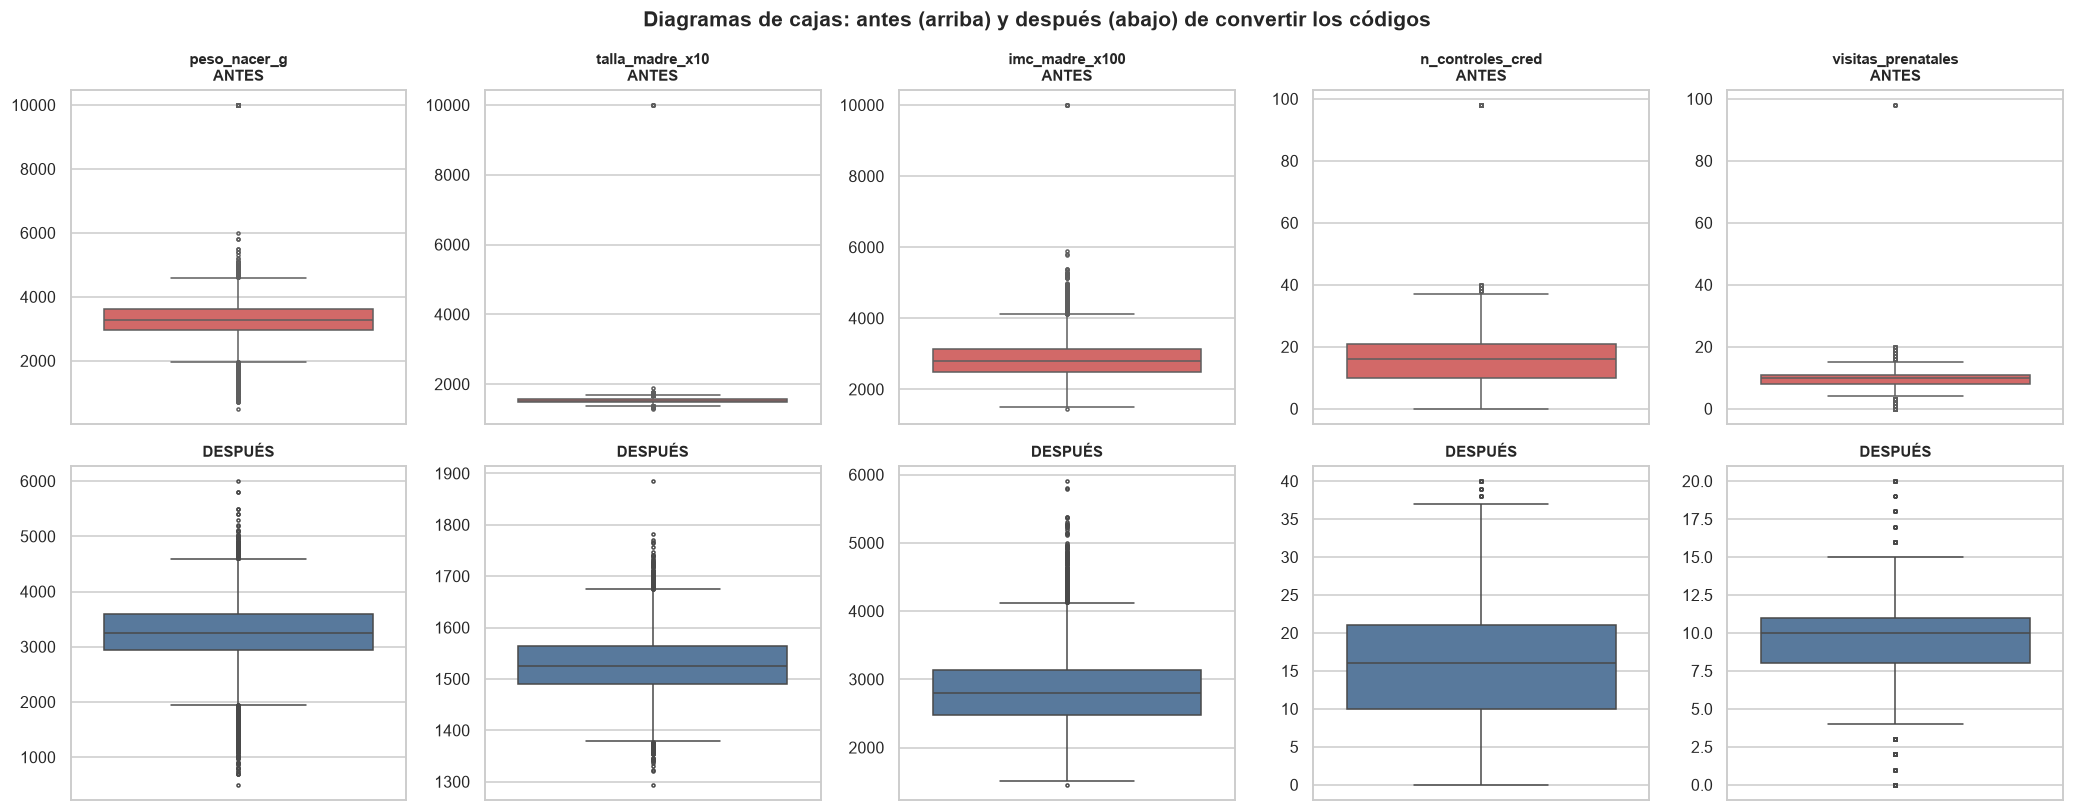

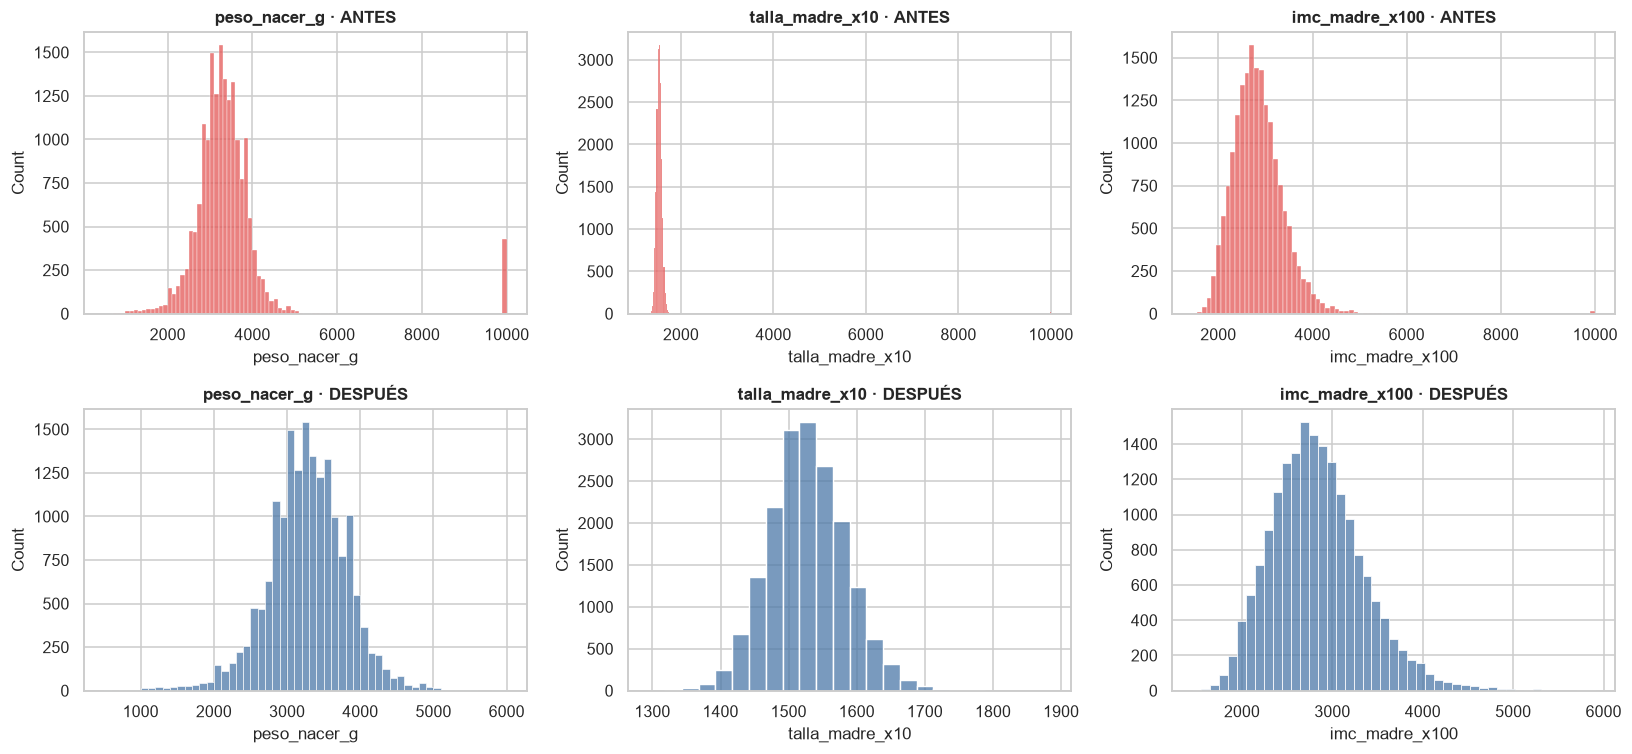

In [6]:
VARS = ["peso_nacer_g", "talla_madre_x10", "imc_madre_x100", "n_controles_cred", "visitas_prenatales"]
fig, axes = plt.subplots(2, 5, figsize=(19, 7.5))
for j, var in enumerate(VARS):
    sns.boxplot(y=base[var], ax=axes[0, j], color=ROJO, fliersize=2)
    axes[0, j].set_title(f"{var}\nANTES", fontsize=10)
    axes[0, j].set_ylabel("")
    sns.boxplot(y=df[var], ax=axes[1, j], color=AZUL, fliersize=2)
    axes[1, j].set_title("DESPUÉS", fontsize=10)
    axes[1, j].set_ylabel("")
fig.suptitle("Diagramas de cajas: antes (arriba) y después (abajo) de convertir los códigos", fontweight="bold")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, (var, ancho) in enumerate([("peso_nacer_g", 100), ("talla_madre_x10", 25), ("imc_madre_x100", 100)]):
    sns.histplot(base[var].dropna(), binwidth=ancho, color=ROJO, ax=axes[0, j])
    axes[0, j].set_title(f"{var} · ANTES")
    sns.histplot(df[var].dropna(), binwidth=ancho, color=AZUL, ax=axes[1, j])
    axes[1, j].set_title(f"{var} · DESPUÉS")
plt.tight_layout()
plt.show()

resumen = pd.DataFrame({"media antes": base[VARS].mean(), "media después": df[VARS].mean(),
                        "máximo antes": base[VARS].max(), "máximo después": df[VARS].max()}).round(1)

In [7]:
nota(f"**Cómo leerlo:** arriba, la caja está aplastada porque los códigos (9998, 9999) estiran la escala hasta 10 000; abajo, la caja ya se ve y los datos ocupan todo el gráfico. En los histogramas, la barra aislada a la derecha desaparece.\n"
     f"**Qué vemos:** sin los códigos, el peso al nacer queda entre {df['peso_nacer_g'].min():.0f} y {df['peso_nacer_g'].max():.0f} g con forma de campana (media {base['peso_nacer_g'].mean():.0f} → {df['peso_nacer_g'].mean():.0f} g) y la talla de la madre entre {df['talla_madre_x10'].min() / 10:.1f} y {df['talla_madre_x10'].max() / 10:.1f} cm (media {base['talla_madre_x10'].mean() / 10:.1f} → {df['talla_madre_x10'].mean() / 10:.1f} cm). Aquí el cambio de la media es moderado porque la mayoría de los códigos estaban en los niños sin objetivo (ya eliminados), pero **los extremos imposibles (9998, 9999) desaparecen por completo**.")
resumen

**Cómo leerlo:** arriba, la caja está aplastada porque los códigos (9998, 9999) estiran la escala hasta 10 000; abajo, la caja ya se ve y los datos ocupan todo el gráfico. En los histogramas, la barra aislada a la derecha desaparece.
**Qué vemos:** sin los códigos, el peso al nacer queda entre 500 y 6000 g con forma de campana (media 3411 → 3251 g) y la talla de la madre entre 129.4 y 188.5 cm (media 153.5 → 152.7 cm). Aquí el cambio de la media es moderado porque la mayoría de los códigos estaban en los niños sin objetivo (ya eliminados), pero **los extremos imposibles (9998, 9999) desaparecen por completo**.

,media antes,media después,máximo antes,máximo después
peso_nacer_g,3410.8,3250.6,9998.0,6000.0
talla_madre_x10,1535.4,1527.4,9999.0,1885.0
imc_madre_x100,2846.2,2839.1,9999.0,5906.0
n_controles_cred,16.7,16.0,98.0,40.0
visitas_prenatales,9.4,9.4,98.0,20.0


### Recodificaciones que no son simples `NaN`
- **`meses_lactancia`:** el código `94` significa *nunca amamantó* → se recodifica a **0 meses** (si quedara 94, el modelo lo leería como casi 8 años).
- **Vacunas:** `1`, `2` y `3` significan todas "vacunado" (carné con fecha, lo dice la madre, marcado en carné) → se unifican en `1`; `0` es no vacunado.

In [8]:
n94 = int((df["meses_lactancia"] == 94).sum())
df["meses_lactancia"] = df["meses_lactancia"].replace({94: 0})
vac_antes = {v: df[v].value_counts(dropna=False).sort_index() for v in ["vacuna_dpt3"]}
for v in ["vacuna_dpt3", "vacuna_polio3", "vacuna_sarampion"]:
    df[v] = df[v].replace({2: 1, 3: 1})
registrar("3b", "meses_lactancia 94 → 0 y vacunas 1-3 → 1", n94)

t = pd.DataFrame({"antes (vacuna_dpt3)": vac_antes["vacuna_dpt3"], "después": df["vacuna_dpt3"].value_counts(dropna=False).sort_index()}).fillna(0).astype(int)
t.index = ["no vacunado" if i == 0 else "vacunado (1)" if i == 1 else "vacunado (2)" if i == 2 else "vacunado (3)" if i == 3 else "vacío" for i in t.index]
nota(f"**Qué vemos:** {n94} niños tenían `meses_lactancia = 94` y ahora tienen 0. En la tabla, `vacuna_dpt3` pasa de cuatro códigos (0, 1, 2, 3) a dos (0 y 1) más los vacíos.")
t

**Qué vemos:** 106 niños tenían `meses_lactancia = 94` y ahora tienen 0. En la tabla, `vacuna_dpt3` pasa de cuatro códigos (0, 1, 2, 3) a dos (0 y 1) más los vacíos.

,antes (vacuna_dpt3),después
no vacunado,3480,3480
vacunado (1),12477,14206
vacunado (2),1729,0
vacío,337,337


## Paso 4 · Reglas lógicas
Valores que son **imposibles** o incoherentes (Semana 04, Parte C). Se cuentan, se corrigen y se vuelve a contar.

In [9]:
def reglas(d):
    return {
        "edad de la madre fuera de 12-49 años": ~d.edad_madre.between(12, 49) & d.edad_madre.notna(),
        "primer parto antes de los 10 años o después de la edad actual": (d.edad_primer_parto < 10) | (d.edad_primer_parto > d.edad_madre),
        "peso al nacer fuera de 500-6 000 g": ~d.peso_nacer_g.between(500, 6000) & d.peso_nacer_g.notna(),
        "talla de la madre fuera de 130-190 cm": ~d.talla_madre_x10.between(1290, 1900) & d.talla_madre_x10.notna(),
        "IMC de la madre fuera de 12-50": ~d.imc_madre_x100.between(1200, 5000) & d.imc_madre_x100.notna(),
        "meses de lactancia mayores que la edad del niño": d.meses_lactancia > d.edad_meses,
        "hogar con 0 menores de 5 años (el niño vive ahí)": d.n_menores_5_hogar == 0,
        "intervalo entre hijos menor de 9 meses": d.intervalo_nac_previo_meses < 9,
    }


antes_r = pd.Series({k: int(m.sum()) for k, m in reglas(df).items()})

# correcciones: lo imposible pasa a NaN; el hogar con 0 menores de 5 años se corrige a 1 (el propio niño)
r0 = reglas(df)
df.loc[r0["IMC de la madre fuera de 12-50"], "imc_madre_x100"] = np.nan
df.loc[r0["meses de lactancia mayores que la edad del niño"], "meses_lactancia"] = np.nan
df.loc[r0["hogar con 0 menores de 5 años (el niño vive ahí)"], "n_menores_5_hogar"] = 1

despues_r = pd.Series({k: int(m.sum()) for k, m in reglas(df).items()})
registrar("4", "Corregir incoherencias lógicas", antes_r.sum())
tabla_r = pd.DataFrame({"antes": antes_r, "después": despues_r})
nota(f"**Qué vemos:** solo {int(antes_r.sum())} valores incumplían alguna regla ({100 * antes_r.sum() / len(df):.2f} % de los niños): casi todos son IMC extremos y unos pocos casos de lactancia mayor que la edad. "
     f"Se corrigieron y la columna *después* queda en cero. Esto confirma que, una vez convertidos los códigos, **los datos son muy coherentes**.")
tabla_r

**Qué vemos:** solo 21 valores incumplían alguna regla (0.12 % de los niños): casi todos son IMC extremos y unos pocos casos de lactancia mayor que la edad. Se corrigieron y la columna *después* queda en cero. Esto confirma que, una vez convertidos los códigos, **los datos son muy coherentes**.

,antes,después
edad de la madre fuera de 12-49 años,0,0
primer parto antes de los 10 años o después de la edad actual,0,0
peso al nacer fuera de 500-6 000 g,0,0
talla de la madre fuera de 130-190 cm,0,0
IMC de la madre fuera de 12-50,18,0
meses de lactancia mayores que la edad del niño,3,0
hogar con 0 menores de 5 años (el niño vive ahí),0,0
intervalo entre hijos menor de 9 meses,0,0


## Paso 5 · Valores atípicos (método RIC)
Un valor es atípico si queda fuera de **[Q1 − 1.5·RIC, Q3 + 1.5·RIC]**, donde Q1 y Q3 son los cuartiles y RIC = Q3 − Q1 (el ancho de la caja). Se aplica **después** de convertir los códigos, para no confundir un código con un extremo real.

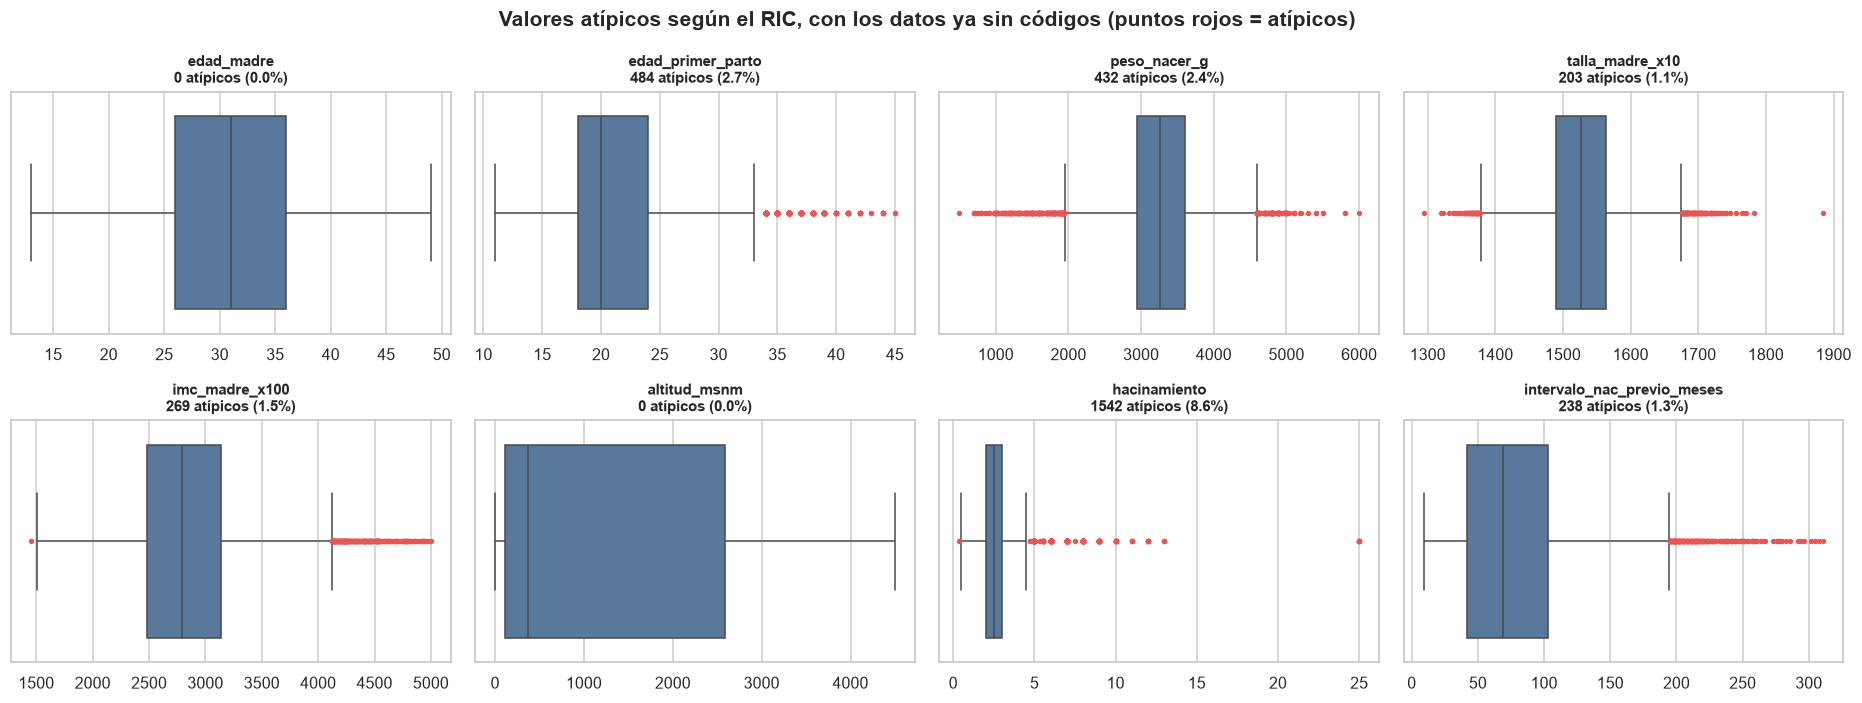

**Cómo leerlo:** cada gráfico es una variable; los puntos rojos son los casos fuera de los bigotes.  
**Qué vemos:** quedan pocos atípicos y son valores **reales** (bebés muy grandes o muy pequeños, madres muy altas o bajas, familias numerosas, partos tardíos). **Decisión: no se eliminan.** Quitar a todo niño con algún extremo en las 5 variables principales haría perder el 9 % de los datos, y justamente el bajo peso al nacer o la baja talla materna son los casos que más interesan. Los árboles (XGBoost) no se afectan por extremos; para regresión lineal se usará escalado robusto o se revisará caso por caso.

,límite inferior,límite superior,atípicos,% atípicos
variable,,,,
edad_madre,11.0,51.0,0,0.0
edad_primer_parto,9.0,33.0,484,2.7
peso_nacer_g,1950.0,4590.0,432,2.4
talla_madre_x10,1379.0,1675.0,203,1.1
imc_madre_x100,1496.5,4124.5,269,1.5
altitud_msnm,-3591.0,6289.0,0,0.0
hacinamiento,0.5,4.5,1542,8.6
intervalo_nac_previo_meses,-49.5,194.5,238,1.3


In [10]:
CONTINUAS = ["edad_madre", "edad_primer_parto", "peso_nacer_g", "talla_madre_x10", "imc_madre_x100", "altitud_msnm", "hacinamiento", "intervalo_nac_previo_meses"]
filas, flags = [], pd.DataFrame(index=df.index)
for var in CONTINUAS:
    s = df[var]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    inf, sup = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    fuera = (s < inf) | (s > sup)
    flags[var] = fuera
    filas.append({"variable": var, "límite inferior": inf, "límite superior": sup, "atípicos": int(fuera.sum()), "% atípicos": 100 * fuera.mean()})
tabla_ric = pd.DataFrame(filas).set_index("variable").round(1)

fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for ax, var in zip(axes.ravel(), CONTINUAS):
    sns.boxplot(x=df[var], ax=ax, color=AZUL, fliersize=2.5, flierprops={"markerfacecolor": ROJO, "markeredgecolor": ROJO})
    ax.set_title(f"{var}\n{int(flags[var].sum())} atípicos ({100 * flags[var].mean():.1f}%)", fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Valores atípicos según el RIC, con los datos ya sin códigos (puntos rojos = atípicos)", fontweight="bold")
plt.tight_layout()
plt.show()

con_alguno = flags[["peso_nacer_g", "talla_madre_x10", "imc_madre_x100", "intervalo_nac_previo_meses", "edad_primer_parto"]].any(axis=1).mean() * 100
registrar("5", "Atípicos por RIC: revisados, no eliminados", 0)
nota(f"**Cómo leerlo:** cada gráfico es una variable; los puntos rojos son los casos fuera de los bigotes.  \n"
     f"**Qué vemos:** quedan pocos atípicos y son valores **reales** (bebés muy grandes o muy pequeños, madres muy altas o bajas, familias numerosas, partos tardíos). "
     f"**Decisión: no se eliminan.** Quitar a todo niño con algún extremo en las 5 variables principales haría perder el {con_alguno:.0f} % de los datos, y justamente el bajo peso al nacer o la baja talla materna son los casos que más interesan. "
     f"Los árboles (XGBoost) no se afectan por extremos; para regresión lineal se usará escalado robusto o se revisará caso por caso.")
tabla_ric

## Paso 6 · Vacunas según la edad
Un niño de 3 meses tiene `vacuna_dpt3 = 0` porque **aún no le toca**, no porque no lo hayan vacunado. Mezclar ambas cosas confunde al modelo. Se deja `NaN` ("no corresponde") cuando el niño es menor que la edad de la dosis: DPT3 y polio3 desde los 6 meses; sarampión desde los 12.

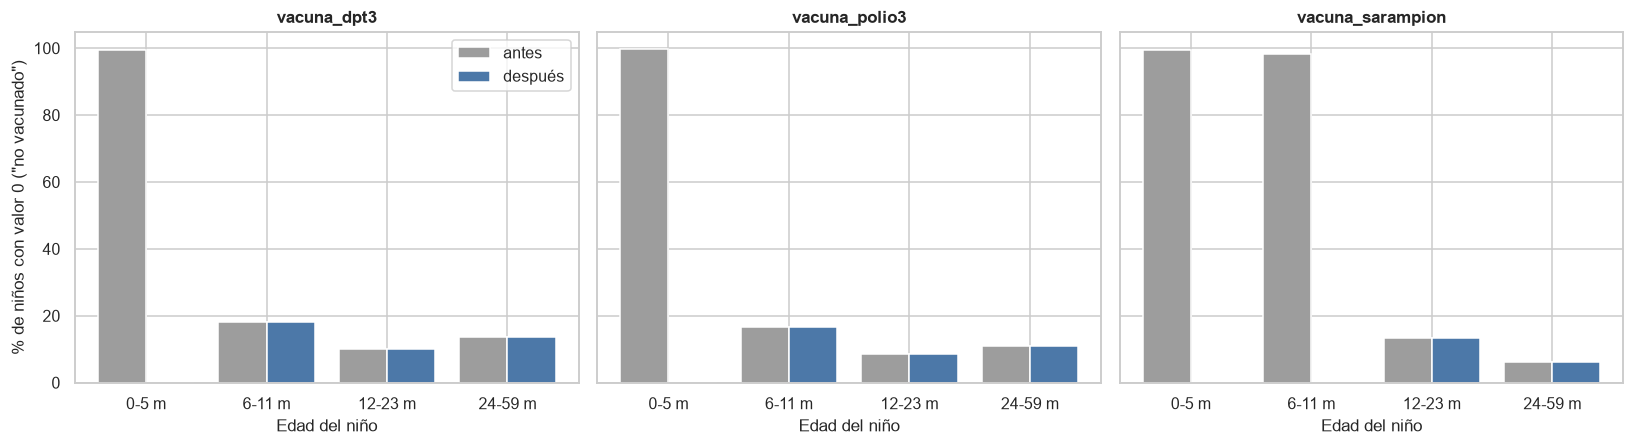

**Cómo leerlo:** cada barra es el % de niños de ese tramo de edad con la vacuna en `0`. Gris = antes; azul = después de dejar en blanco a los que aún no tienen edad.  
**Qué vemos:** antes, casi el 100 % de los bebés de 0-5 meses figuraban como "no vacunados" en DPT3 y polio (y el 98 % de los de 6-11 en sarampión). Eso era un espejismo. Después, las barras azules muestran la **cobertura real**: entre un 6 % y un 18 % de los niños con edad para la dosis aún no la tiene. Se marcaron 5,652 valores como "no corresponde".

In [11]:
EDAD_DOSIS = {"vacuna_dpt3": 6, "vacuna_polio3": 6, "vacuna_sarampion": 12}
grupo = pd.cut(df["edad_meses"], [-1, 5, 11, 23, 59], labels=["0-5 m", "6-11 m", "12-23 m", "24-59 m"])
antes_v = {v: (df[v] == 0).groupby(grupo, observed=True).mean() * 100 for v in EDAD_DOSIS}

n_marcados = 0
for v, edad_min in EDAD_DOSIS.items():
    mascara = df["edad_meses"] < edad_min
    n_marcados += int(mascara.sum())
    df.loc[mascara, v] = np.nan
registrar("6", "Vacunas: NaN si el niño aún no tiene edad para la dosis", n_marcados)
despues_v = {v: (df[v] == 0).groupby(grupo, observed=True).mean() * 100 for v in EDAD_DOSIS}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, v in zip(axes, EDAD_DOSIS):
    x = np.arange(4)
    ax.bar(x - 0.2, antes_v[v].values, width=0.4, color=GRIS, label="antes")
    ax.bar(x + 0.2, despues_v[v].values, width=0.4, color=AZUL, label="después")
    ax.set_xticks(x)
    ax.set_xticklabels(antes_v[v].index)
    ax.set_title(v)
    ax.set_xlabel("Edad del niño")
axes[0].set_ylabel("% de niños con valor 0 (\"no vacunado\")")
axes[0].legend()
plt.tight_layout()
plt.show()
nota(f"**Cómo leerlo:** cada barra es el % de niños de ese tramo de edad con la vacuna en `0`. Gris = antes; azul = después de dejar en blanco a los que aún no tienen edad.  \n"
     f"**Qué vemos:** antes, casi el 100 % de los bebés de 0-5 meses figuraban como \"no vacunados\" en DPT3 y polio (y el 98 % de los de 6-11 en sarampión). Eso era un espejismo. "
     f"Después, las barras azules muestran la **cobertura real**: entre un 6 % y un 18 % de los niños con edad para la dosis aún no la tiene. Se marcaron {n_marcados:,} valores como \"no corresponde\".")

## Paso 7 · Codificación de variables
Los modelos trabajan con números, pero un número solo es una **escala** si de verdad se ordena. Tres tratamientos (Semana 04):

| Tipo | Ejemplo | Tratamiento |
|---|---|---|
| **Binaria** | sexo, área, ¿recibe Juntos? | 0 / 1 (se eligen nombres que digan qué significa el 1) |
| **Ordinal** | riqueza, educación, anemia | números **en el orden real** (nunca `LabelEncoder`) |
| **Nominal** | departamento, lengua, lugar de parto | sin orden: *category* (XGBoost) o *One-Hot* |

In [12]:
# 7.1 Binarias a 0/1 y anemia ordenada de menor a mayor gravedad
MAPAS = {
    "sexo_nino": {1: 0, 2: 1},                                   # 0 hombre, 1 mujer
    "area_residencia": {1: 0, 2: 1},                             # 0 urbano, 1 rural
    "lactancia_exclusiva_6m": {1: 1, 2: 0},
    "hierro_jarabe_7d": {1: 1, 2: 0},
    "micronutrientes_polvo_7d": {1: 1, 2: 0},
    "hogar_juntos": {1: 1, 2: 0},
    "hogar_vaso_leche": {1: 1, 2: 0},
    "nivel_anemia_nino": {4: 0, 3: 1, 2: 2, 1: 3},               # 0 sin anemia ... 3 grave
}
RENOMBRAR = {"sexo_nino": "nino_mujer", "area_residencia": "area_rural", "nivel_anemia_nino": "severidad_anemia_nino"}

tabla_cod = []
for col, mapa in MAPAS.items():
    no_nulos = df[col].notna().sum()
    antes = df[col].value_counts().sort_index().to_dict()
    df[col] = df[col].map(mapa)
    assert df[col].notna().sum() == no_nulos, f"{col}: el mapa perdió valores"
    tabla_cod.append({"variable": col, "antes": antes, "después": df[col].value_counts().sort_index().to_dict()})
df = df.rename(columns=RENOMBRAR)
FEATURES = [RENOMBRAR.get(c, c) for c in FEATURES]
CATEG = [RENOMBRAR.get(c, c) for c in CATEG]
registrar("7a", "Recodificar 8 variables (binarias y anemia) y renombrar 3 [= variables afectadas]", len(MAPAS))
pd.DataFrame(tabla_cod).set_index("variable")

,antes,después
variable,,
sexo_nino,"{1: 9260, 2: 8763}","{0: 9260, 1: 8763}"
area_residencia,"{1.0: 12818, 2.0: 5205}","{0: 12818, 1: 5205}"
lactancia_exclusiva_6m,"{1.0: 7795, 2.0: 2069}","{0.0: 2069, 1.0: 7795}"
hierro_jarabe_7d,"{1.0: 2232, 2.0: 15104}","{0.0: 15104, 1.0: 2232}"
micronutrientes_polvo_7d,"{1.0: 1966, 2.0: 15370}","{0.0: 15370, 1.0: 1966}"
hogar_juntos,"{1.0: 4898, 2.0: 13118}","{0.0: 13118, 1.0: 4898}"
hogar_vaso_leche,"{1.0: 6688, 2.0: 11327}","{0.0: 11327, 1.0: 6688}"
nivel_anemia_nino,"{1.0: 24, 2.0: 1649, 3.0: 4073, 4.0: 10889}","{0.0: 10889, 1.0: 4073, 2.0: 1649, 3.0: 24}"


**Qué vemos:** cada variable pasó de códigos arbitrarios (1 = sí / 2 = no, 4 = sin anemia…) a un 0/1 o a una escala que crece con la gravedad. Los nombres nuevos indican qué es el 1: `nino_mujer` (1 = mujer), `area_rural` (1 = rural), `severidad_anemia_nino` (0 = sin anemia … 3 = grave).

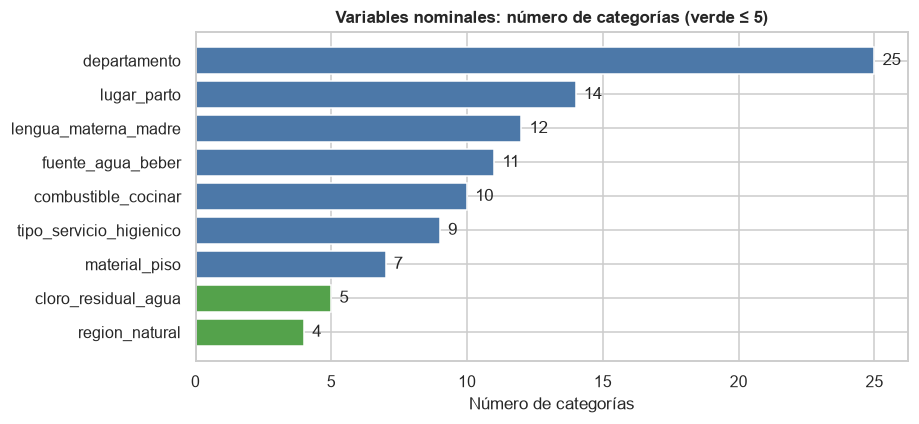

**Cómo leerlo:** cada barra es una variable nominal y su longitud es cuántas categorías distintas tiene.  
**Qué vemos:** `departamento` tiene 25 categorías y `lugar_parto` 14: con *One-Hot* crearían demasiadas columnas, por eso XGBoost las recibe como tipo `category`. Las de pocas categorías (como `region_natural`, que se convertiría en las 4 columnas region_1.0, region_2.0, region_3.0, region_4.0) pueden ir en *One-Hot* para la regresión lineal.

In [13]:
# 7.2 Nominales: cuántas categorías tiene cada una (decide One-Hot o category)
card = df[CATEG].nunique().sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(card.index, card.values, color=[VERDE if v <= 5 else AZUL for v in card.values])
for i, v in enumerate(card.values):
    ax.text(v + 0.3, i, str(v), va="center")
ax.set_xlabel("Número de categorías")
ax.set_title("Variables nominales: número de categorías (verde ≤ 5)")
plt.tight_layout()
plt.show()

ejemplo = pd.get_dummies(df["region_natural"].astype("category"), prefix="region")
nota(f"**Cómo leerlo:** cada barra es una variable nominal y su longitud es cuántas categorías distintas tiene.  \n"
     f"**Qué vemos:** `departamento` tiene {card['departamento']} categorías y `lugar_parto` {card['lugar_parto']}: con *One-Hot* crearían demasiadas columnas, por eso XGBoost las recibe como tipo `category`. "
     f"Las de pocas categorías (como `region_natural`, que se convertiría en las {ejemplo.shape[1]} columnas {', '.join(ejemplo.columns)}) pueden ir en *One-Hot* para la regresión lineal.")

In [14]:
# 7.3 Por qué NO usar LabelEncoder con una variable ordinal (error común de la guía)
niveles = pd.Series(["sin anemia", "leve", "moderada", "grave"])
orden_real = {"sin anemia": 0, "leve": 1, "moderada": 2, "grave": 3}
pd.DataFrame({"categoría": niveles, "LabelEncoder (orden alfabético ✗)": LabelEncoder().fit_transform(niveles),
              "mapa manual (orden real ✓)": niveles.map(orden_real)})

,categoría,LabelEncoder (orden alfabético ✗),mapa manual (orden real ✓)
0,sin anemia,3,0
1,leve,1,1
2,moderada,2,2
3,grave,0,3


**Qué vemos:** `LabelEncoder` ordena alfabéticamente y asigna *grave = 0* y *sin anemia = 3*, el orden **contrario**. Por eso las ordinales se codificaron con un mapa manual, como en 7.1.

## Paso 8 · Diagnóstico de los valores vacíos
Tras la limpieza hay vacíos de dos tipos: los que **faltan** (no se midió o no se supo) y los que **no aplican** (la pregunta no corresponde a ese niño). No se tratan igual.

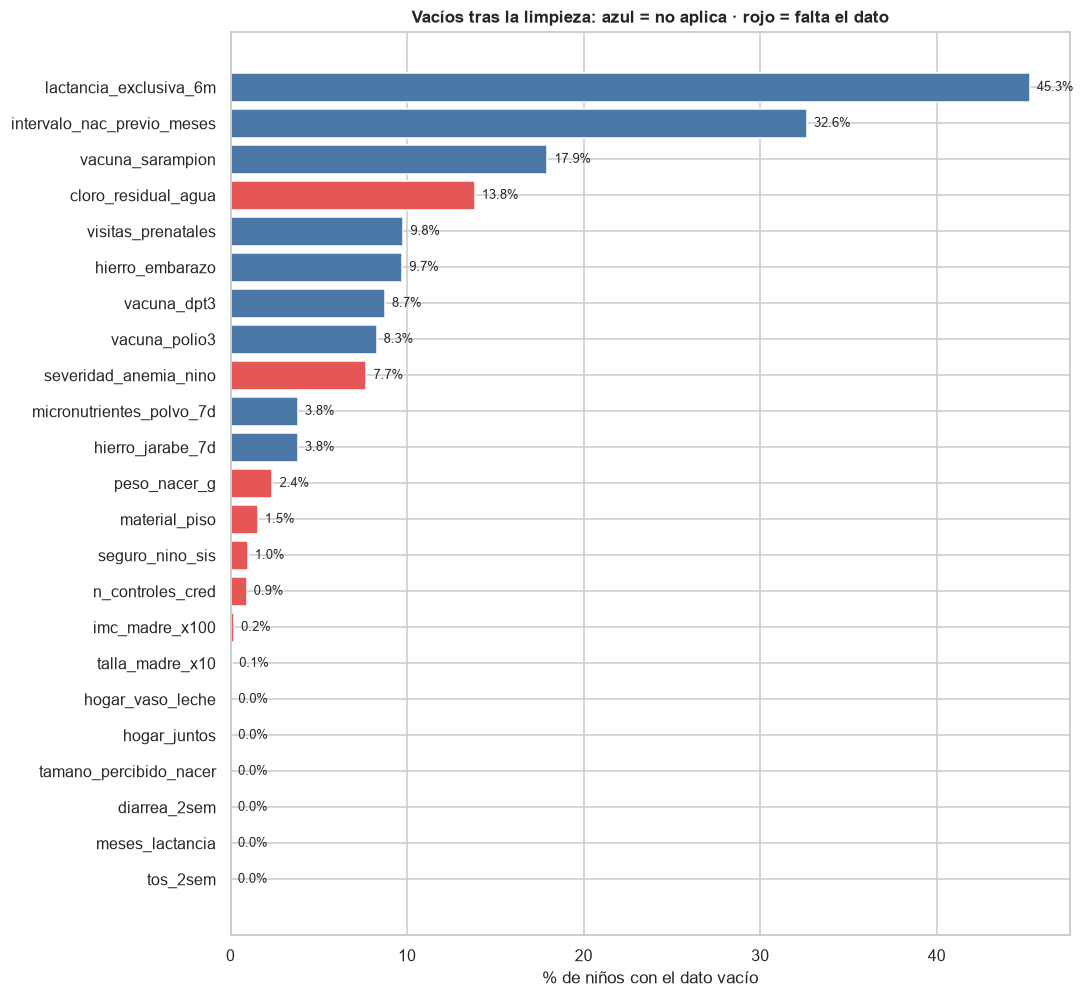

**Cómo leerlo:** cada barra es una variable; el color dice *por qué* está vacía.  
**Qué vemos:** la mayoría de los vacíos (azul) son preguntas que **no aplican**: se dejan como `NaN`, porque rellenarlos inventaría información (por ejemplo, darle "intervalo entre hijos" a un primogénito). Las variables con vacíos rojos (anemia no medida, cloro, IMC y talla de la madre…) son pocas y con porcentajes pequeños. **Estrategia:** el dataset guardado conserva los `NaN` (XGBoost los maneja); para regresión lineal se imputa dentro del *Pipeline*, con estadísticos calculados solo en *train* (paso 10).

In [15]:
MOTIVO = {
    "lactancia_exclusiva_6m": "No aplica (menor de 6 meses) o sin registro",
    "intervalo_nac_previo_meses": "No aplica (primogénito)",
    "visitas_prenatales": "No aplica (solo se pregunta por el hijo menor)",
    "hierro_embarazo": "No aplica (solo se pregunta por el hijo menor)",
    "hierro_jarabe_7d": "No aplica (menor de 6 meses)",
    "micronutrientes_polvo_7d": "No aplica (menor de 6 meses)",
    "vacuna_dpt3": "No aplica (aún no tiene edad)",
    "vacuna_polio3": "No aplica (aún no tiene edad)",
    "vacuna_sarampion": "No aplica (aún no tiene edad)",
}
vac = df[FEATURES].isna().mean().mul(100)
vac = vac[vac > 0].sort_values()
motivos = [MOTIVO.get(v, "Falta el dato (no medido / no sabe)") for v in vac.index]
paleta = {"Falta el dato (no medido / no sabe)": ROJO}
colores = [paleta.get(m, AZUL) for m in motivos]

fig, ax = plt.subplots(figsize=(10, 0.34 * len(vac) + 1.4))
ax.barh(vac.index, vac.values, color=colores)
for i, v in enumerate(vac.values):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("% de niños con el dato vacío")
ax.set_title("Vacíos tras la limpieza: azul = no aplica · rojo = falta el dato")
plt.tight_layout()
plt.show()

total_vacios = int(df[FEATURES].isna().sum().sum())
nota(f"**Cómo leerlo:** cada barra es una variable; el color dice *por qué* está vacía.  \n"
     f"**Qué vemos:** la mayoría de los vacíos (azul) son preguntas que **no aplican**: se dejan como `NaN`, porque rellenarlos inventaría información (por ejemplo, darle \"intervalo entre hijos\" a un primogénito). "
     f"Las variables con vacíos rojos (anemia no medida, cloro, IMC y talla de la madre…) son pocas y con porcentajes pequeños. "
     f"**Estrategia:** el dataset guardado conserva los `NaN` (XGBoost los maneja); para regresión lineal se imputa dentro del *Pipeline*, con estadísticos calculados solo en *train* (paso 10).")

## Paso 9 · División train/test por conglomerado
Antes de calcular cualquier media, mediana o escala, se separa **entrenamiento (80 %)** y **prueba (20 %)**. Se hace por **conglomerado**: todos los niños de un mismo conglomerado van al mismo lado, así el modelo se evalúa en zonas que no vio. La partición queda guardada en la columna `particion`.

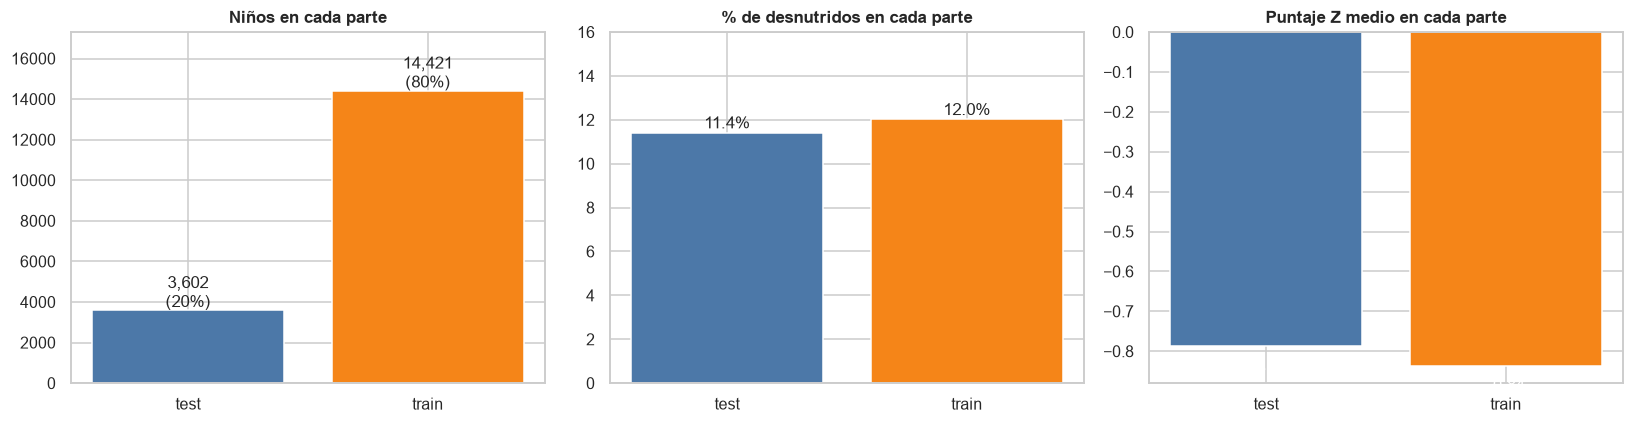

**Cómo leerlo:** si la división es buena, las dos partes deben *parecerse* en prevalencia y en puntaje Z medio (las barras de la derecha y del centro casi iguales).  
**Qué vemos:** train tiene 14,421 niños y test 3,602; el porcentaje de desnutridos es 12.0 % y 11.4 %. Conglomerados presentes en ambas partes: **0** (debe ser 0).

In [16]:
y = df["desnutricion_cronica"].astype(int)
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(df, y, groups=df["conglomerado"]))
df["particion"] = "train"
df.loc[te, "particion"] = "test"
registrar("9", "Partición train/test por conglomerado (80/20)", len(te))

resumen = df.groupby("particion").agg(niños=("caseid", "size"), conglomerados=("conglomerado", "nunique"),
                                      prevalencia=("desnutricion_cronica", "mean"), haz_medio=("haz", "mean"))
comun = set(df.loc[df.particion == "train", "conglomerado"]) & set(df.loc[df.particion == "test", "conglomerado"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(resumen.index, resumen["niños"], color=[AZUL, NARANJA])
for i, v in enumerate(resumen["niños"]):
    axes[0].text(i, v + 150, f"{v:,}\n({100 * v / len(df):.0f}%)", ha="center")
axes[0].set_ylim(0, resumen["niños"].max() * 1.2)
axes[0].set_title("Niños en cada parte")
axes[1].bar(resumen.index, resumen["prevalencia"] * 100, color=[AZUL, NARANJA])
for i, v in enumerate(resumen["prevalencia"] * 100):
    axes[1].text(i, v + 0.2, f"{v:.1f}%", ha="center")
axes[1].set_ylim(0, 16)
axes[1].set_title("% de desnutridos en cada parte")
axes[2].bar(resumen.index, resumen["haz_medio"], color=[AZUL, NARANJA])
for i, v in enumerate(resumen["haz_medio"]):
    axes[2].text(i, v - 0.06, f"{v:.2f}", ha="center", color="white")
axes[2].set_title("Puntaje Z medio en cada parte")
plt.tight_layout()
plt.show()
nota(f"**Cómo leerlo:** si la división es buena, las dos partes deben *parecerse* en prevalencia y en puntaje Z medio (las barras de la derecha y del centro casi iguales).  \n"
     f"**Qué vemos:** train tiene {resumen.loc['train', 'niños']:,} niños y test {resumen.loc['test', 'niños']:,}; el porcentaje de desnutridos es {resumen.loc['train', 'prevalencia'] * 100:.1f} % y {resumen.loc['test', 'prevalencia'] * 100:.1f} %. "
     f"Conglomerados presentes en ambas partes: **{len(comun)}** (debe ser 0).")
assert len(comun) == 0

## Paso 10 · Imputación y escalado (solo con *train*)
Imputar (rellenar vacíos) y escalar son transformaciones que **aprenden** de los datos (una mediana, una media). Si se calculan con todo el dataset, el modelo "ve" información de la prueba (*data leakage*). La regla (Semana 04): **`fit` solo en train, `transform` en train y test**.

Estos pasos **no se guardan** en `dataset_limpio.csv` (XGBoost no los necesita; la regresión lineal los hace dentro de su *Pipeline*). Aquí se muestran para entender su efecto.

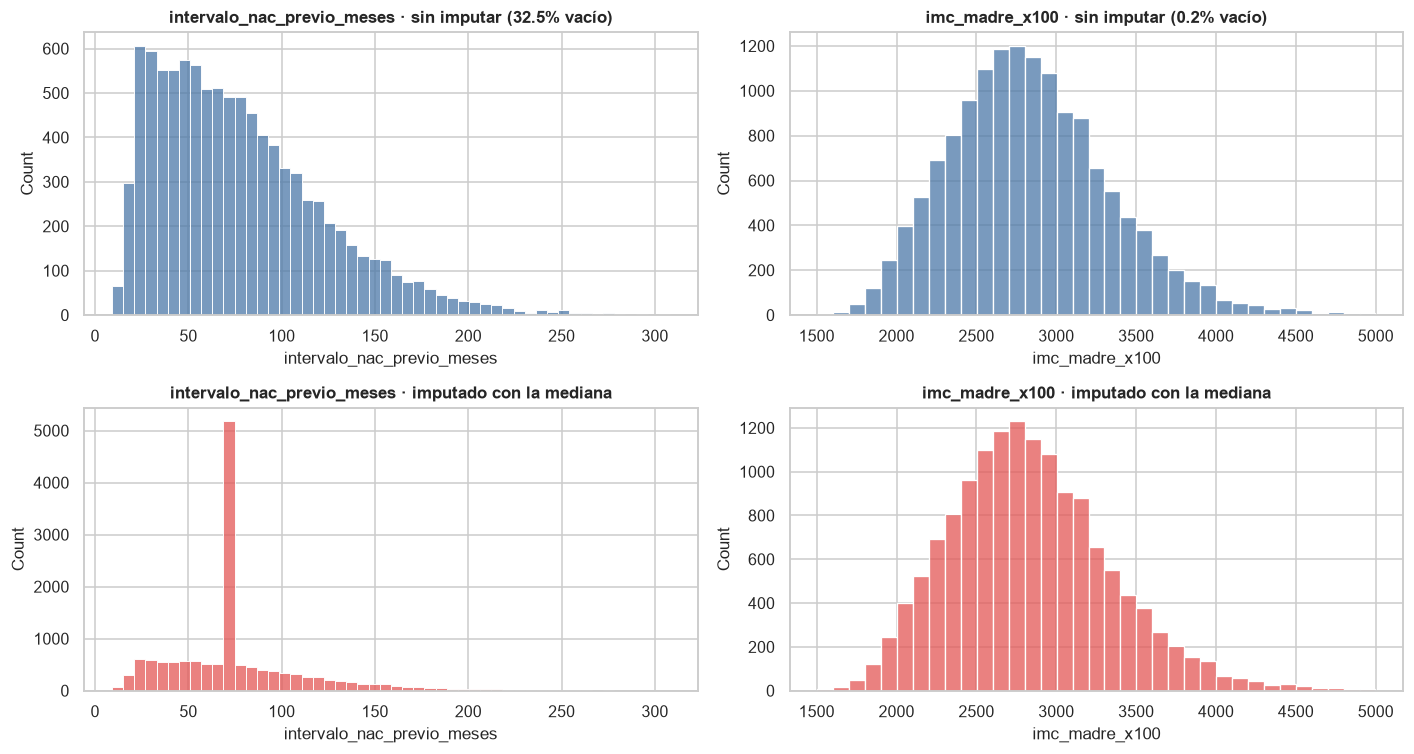

**Cómo leerlo:** arriba, la distribución real; abajo, la que resulta de rellenar los vacíos con la mediana de *train*.  
**Qué vemos:** donde faltan pocos datos (IMC, 0.2 %) la imputación casi no cambia la forma. Donde faltan muchos (intervalo entre hijos, 33 %) aparece una **barra gigante en la mediana** que deforma la variable. Por eso solo se imputa en modelos que lo exigen (regresión lineal) y **no** en el archivo guardado.

In [17]:
NUM = [c for c in FEATURES if c not in CATEG]
train, test = df[df.particion == "train"], df[df.particion == "test"]

imp = SimpleImputer(strategy="median").fit(train[NUM])
train_imp = pd.DataFrame(imp.transform(train[NUM]), columns=NUM, index=train.index)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for j, (var, ancho) in enumerate([("intervalo_nac_previo_meses", 6), ("imc_madre_x100", 100)]):
    sns.histplot(train[var].dropna(), binwidth=ancho, color=AZUL, ax=axes[0, j])
    axes[0, j].set_title(f"{var} · sin imputar ({train[var].isna().mean() * 100:.1f}% vacío)")
    sns.histplot(train_imp[var], binwidth=ancho, color=ROJO, ax=axes[1, j])
    axes[1, j].set_title(f"{var} · imputado con la mediana")
plt.tight_layout()
plt.show()
nota(f"**Cómo leerlo:** arriba, la distribución real; abajo, la que resulta de rellenar los vacíos con la mediana de *train*.  \n"
     f"**Qué vemos:** donde faltan pocos datos (IMC, {train['imc_madre_x100'].isna().mean() * 100:.1f} %) la imputación casi no cambia la forma. "
     f"Donde faltan muchos (intervalo entre hijos, {train['intervalo_nac_previo_meses'].isna().mean() * 100:.0f} %) aparece una **barra gigante en la mediana** que deforma la variable. "
     f"Por eso solo se imputa en modelos que lo exigen (regresión lineal) y **no** en el archivo guardado.")

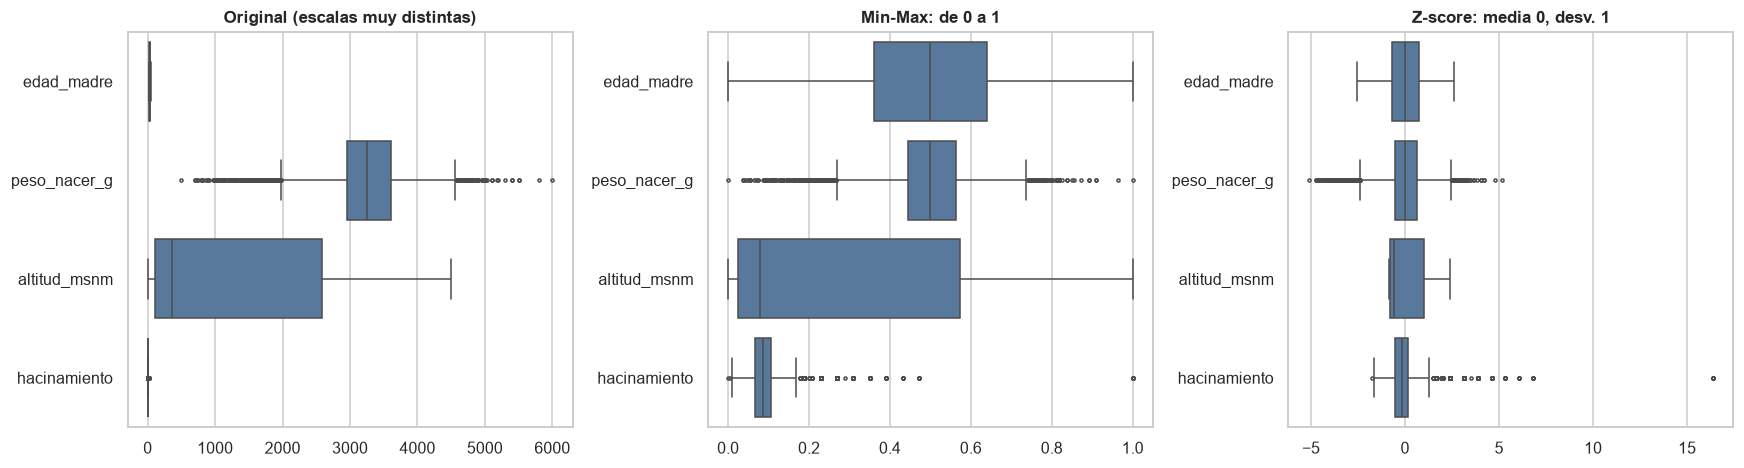

**Cómo leerlo:** las mismas cuatro variables en tres escalas. Izquierda: la altitud (hasta 4 500) domina y las demás se ven como una línea; centro: todo entre 0 y 1; derecha: todo alrededor de 0.  
**Qué vemos:** el escalado pone las variables a la par (necesario para regresión lineal; los árboles no lo necesitan). Prueba de que no hay fuga: en *train* la media es 0 y la desviación 1 **por construcción**, mientras que en *test* son parecidas pero **no exactas**, porque el escalador solo aprendió de *train*.

,train · media,train · desv.,test · media,test · desv.
edad_madre,0.0,1.0,0.003,0.987
peso_nacer_g,-0.0,1.0,0.019,1.006
altitud_msnm,-0.0,1.0,0.036,1.007
hacinamiento,-0.0,1.0,0.002,0.946


In [18]:
# Escalado: fit en train, transform en train y test
ESC = ["edad_madre", "peso_nacer_g", "altitud_msnm", "hacinamiento"]
trn = train_imp[ESC]
tst = pd.DataFrame(imp.transform(test[NUM]), columns=NUM, index=test.index)[ESC]
z, mm = StandardScaler().fit(trn), MinMaxScaler().fit(trn)
z_tr, z_te = pd.DataFrame(z.transform(trn), columns=ESC), pd.DataFrame(z.transform(tst), columns=ESC)
mm_tr = pd.DataFrame(mm.transform(trn), columns=ESC)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, datos, titulo in zip(axes, [trn.reset_index(drop=True), mm_tr, z_tr], ["Original (escalas muy distintas)", "Min-Max: de 0 a 1", "Z-score: media 0, desv. 1"]):
    sns.boxplot(data=datos, ax=ax, orient="h", color=AZUL, fliersize=2)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

comprobacion = pd.DataFrame({"train · media": z_tr.mean(), "train · desv.": z_tr.std(), "test · media": z_te.mean(), "test · desv.": z_te.std()}).round(3)
nota("**Cómo leerlo:** las mismas cuatro variables en tres escalas. Izquierda: la altitud (hasta 4 500) domina y las demás se ven como una línea; centro: todo entre 0 y 1; derecha: todo alrededor de 0.  \n"
     "**Qué vemos:** el escalado pone las variables a la par (necesario para regresión lineal; los árboles no lo necesitan). Prueba de que no hay fuga: en *train* la media es 0 y la desviación 1 **por construcción**, mientras que en *test* son parecidas pero **no exactas**, porque el escalador solo aprendió de *train*.")
comprobacion

## Paso 11 · Verificación y guardado
Antes de guardar se comprueba, con `assert`, que cada problema detectado en el notebook 02 quedó resuelto.

In [19]:
INVERSO = {v: k for k, v in RENOMBRAR.items()}
cod_restantes = sum(int(df[v].isin(c).sum()) for v, c in CODIGOS.items() if v in df.columns)          # variables que no cambiaron de nombre
cod_restantes += int(df["severidad_anemia_nino"].isin([9]).sum())
chequeos = {
    "Sin niños sin objetivo": df["haz"].notna().all() and df["desnutricion_cronica"].notna().all(),
    "Sin filas duplicadas": not df.duplicated().any(),
    "Sin códigos especiales sin convertir": cod_restantes == 0,
    "Peso al nacer en 500-6 000 g": df["peso_nacer_g"].dropna().between(500, 6000).all(),
    "Talla de la madre en 129-190 cm": df["talla_madre_x10"].dropna().between(1290, 1900).all(),
    "IMC de la madre en 12-50": df["imc_madre_x100"].dropna().between(1200, 5000).all(),
    "Lactancia no mayor que la edad": (df["meses_lactancia"].dropna() <= df.loc[df["meses_lactancia"].notna(), "edad_meses"]).all(),
    "Binarias solo con 0 y 1": all(set(df[c].dropna().unique()) <= {0, 1} for c in ["nino_mujer", "area_rural", "lactancia_exclusiva_6m", "hierro_jarabe_7d", "hogar_juntos", "hogar_vaso_leche", "vacuna_dpt3", "vacuna_sarampion", "seguro_nino_sis", "antiparasitario_12m"]),
    "Anemia entre 0 y 3": df["severidad_anemia_nino"].dropna().between(0, 3).all(),
    "Train y test sin conglomerados en común": len(comun) == 0,
}
tabla_chk = pd.DataFrame({"comprobación": list(chequeos), "resultado": ["✓ correcto" if bool(v) else "✗ FALLA" for v in chequeos.values()]})
assert all(bool(v) for v in chequeos.values()), tabla_chk
tabla_chk

,comprobación,resultado
0,Sin niños sin objetivo,✓ correcto
1,Sin filas duplicadas,✓ correcto
2,Sin códigos especiales sin convertir,✓ correcto
3,Peso al nacer en 500-6 000 g,✓ correcto
4,Talla de la madre en 129-190 cm,✓ correcto
5,IMC de la madre en 12-50,✓ correcto
6,Lactancia no mayor que la edad,✓ correcto
7,Binarias solo con 0 y 1,✓ correcto
8,Anemia entre 0 y 3,✓ correcto
9,Train y test sin conglomerados en común,✓ correcto


In [20]:
# Antes vs. después
resumen_final = pd.DataFrame({
    "niños": [len(crudo), len(df)],
    "variables predictoras": [42, len(FEATURES)],
    "códigos especiales sin convertir": [int(sum(crudo[v].isin(c).sum() for v, c in CODIGOS.items())), cod_restantes],
    "valores vacíos en las features": [int(crudo[dic.loc[dic.rol == "feature", "nombre"]].isna().sum().sum()), int(df[FEATURES].isna().sum().sum())],
}, index=["crudo", "limpio"])
display(resumen_final)
nota("**Qué vemos:** los códigos especiales pasan de miles a **cero**. Los vacíos en las variables *aumentan*, y es lo correcto: antes los “no sabe” estaban escondidos como números; ahora se reconocen como lo que son. El número de variables predictoras no cambia (42).")
display(pd.DataFrame(LOG).set_index("paso"))

,niños,variables predictoras,códigos especiales sin convertir,valores vacíos en las features
crudo,18841,42,6561,23887
limpio,18023,42,0,30249


**Qué vemos:** los códigos especiales pasan de miles a **cero**. Los vacíos en las variables *aumentan*, y es lo correcto: antes los “no sabe” estaban escondidos como números; ahora se reconocen como lo que son. El número de variables predictoras no cambia (42).

,acción,afectados,filas,columnas
paso,,,,
1,Eliminar niños sin puntaje Z válido,818,18023,50
2,Eliminar duplicados exactos,0,18023,50
3,"Códigos especiales (9996-9999, 98, 9, 8) a NaN",5237,18023,50
3b,meses_lactancia 94 → 0 y vacunas 1-3 → 1,106,18023,50
4,Corregir incoherencias lógicas,21,18023,50
5,"Atípicos por RIC: revisados, no eliminados",0,18023,50
6,Vacunas: NaN si el niño aún no tiene edad para...,5652,18023,50
7a,Recodificar 8 variables (binarias y anemia) y ...,8,18023,50
9,Partición train/test por conglomerado (80/20),3602,18023,51


### Guardar
Se guardan: `dataset_limpio.csv` (con la partición `train`/`test`), `diccionario_limpio.csv` (qué se hizo en cada variable) y `registro_limpieza.csv` (los pasos).

In [21]:
TRAT = {
    "peso_nacer_g": "Códigos 9996/9998 → NaN", "talla_madre_x10": "Código 9999 → NaN", "imc_madre_x100": "Códigos 9998/9999 → NaN; IMC fuera de 12-50 → NaN",
    "visitas_prenatales": "Código 98 → NaN", "n_controles_cred": "Código 98 → NaN", "meses_lactancia": "98 → NaN; 94 (nunca amamantó) → 0; mayor que la edad → NaN",
    "cloro_residual_agua": "Códigos 6 y 9 → NaN", "tamano_percibido_nacer": "Código 8 → NaN",
    "nino_mujer": "Recodificada: 0 hombre, 1 mujer (antes sexo_nino 1/2)", "area_rural": "Recodificada: 0 urbano, 1 rural (antes area_residencia 1/2)",
    "severidad_anemia_nino": "Código 9 → NaN; reordenada: 0 sin anemia … 3 grave (antes nivel_anemia_nino)",
    "lactancia_exclusiva_6m": "8 → NaN; 1 sí / 0 no", "hierro_jarabe_7d": "8 → NaN; 1 sí / 0 no", "micronutrientes_polvo_7d": "8 → NaN; 1 sí / 0 no",
    "hogar_juntos": "8 → NaN; 1 sí / 0 no", "hogar_vaso_leche": "8 → NaN; 1 sí / 0 no",
    "vacuna_dpt3": "8 → NaN; 1-3 → 1; NaN si el niño es menor de 6 meses", "vacuna_polio3": "8 → NaN; 1-3 → 1; NaN si es menor de 6 meses",
    "vacuna_sarampion": "8 → NaN; 1-3 → 1; NaN si es menor de 12 meses", "n_menores_5_hogar": "0 → 1 (el propio niño)",
    "hierro_embarazo": "8 → NaN", "diarrea_2sem": "8 → NaN", "tos_2sem": "8 → NaN", 
}
DESC = {
    "nino_mujer": "0 = hombre, 1 = mujer", "area_rural": "0 = urbano, 1 = rural",
    "severidad_anemia_nino": "0 sin anemia, 1 leve, 2 moderada, 3 grave (ajustada por altitud)",
    "lactancia_exclusiva_6m": "1 sí, 0 no (vacío si no aplica)", "hierro_jarabe_7d": "1 sí, 0 no", "micronutrientes_polvo_7d": "1 sí, 0 no",
    "hogar_juntos": "1 sí, 0 no", "hogar_vaso_leche": "1 sí, 0 no",
    "vacuna_dpt3": "1 vacunado, 0 no (vacío si aún no corresponde)", "vacuna_polio3": "1 vacunado, 0 no (vacío si aún no corresponde)",
    "vacuna_sarampion": "1 vacunado, 0 no (vacío si aún no corresponde)", "meses_lactancia": "Meses de lactancia (0 = nunca amamantó)",
}
d = dic.copy()
d["nombre_limpio"] = d["nombre"].map(lambda n: RENOMBRAR.get(n, n))
orden_cols = ["caseid", "hhid", "conglomerado", "factor_ponderacion", "particion"] + FEATURES + ["haz", "desnutricion_cronica"]
d = d[d["nombre_limpio"].isin(orden_cols)].copy()
d["tratamiento"] = d["nombre_limpio"].map(lambda n: TRAT.get(n, "Sin cambios"))
d["descripcion_limpia"] = d.apply(lambda r: DESC.get(r["nombre_limpio"], r["descripcion"]), axis=1)
extra = pd.DataFrame([{"bloque": "Partición", "nombre_limpio": "particion", "rol": "grupo", "tipo": "identificador", "tratamiento": "Nueva: train/test por conglomerado (80/20, semilla 42)",
                       "descripcion_limpia": "train o test; todos los niños de un conglomerado van juntos"}])
d = pd.concat([d, extra], ignore_index=True)
d = d.set_index("nombre_limpio").loc[orden_cols].reset_index()[["bloque", "nombre_limpio", "nombre", "rol", "tipo", "tratamiento", "descripcion_limpia"]]
d = d.rename(columns={"nombre": "nombre_crudo", "nombre_limpio": "nombre"})

orden = ["caseid", "hhid", "conglomerado", "factor_ponderacion", "particion"] + FEATURES + ["haz", "desnutricion_cronica"]
limpio = df[orden]
limpio.to_csv(SALIDA / "dataset_limpio.csv", index=False, encoding="utf-8")
d.to_csv(SALIDA / "diccionario_limpio.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(LOG).to_csv(SALIDA / "registro_limpieza.csv", index=False, encoding="utf-8-sig")

assert hashlib.md5(RUTA_CRUDO.read_bytes()).hexdigest() == HUELLA_CRUDO, "¡El archivo crudo cambió!"
print("Guardado:", "dataset_limpio.csv", limpio.shape, "| diccionario_limpio.csv", d.shape, "| registro_limpieza.csv")
print("El archivo crudo NO se modificó (misma huella):", HUELLA_CRUDO[:10] + "…")

Guardado: dataset_limpio.csv (18023, 49) | diccionario_limpio.csv (49, 7) | registro_limpieza.csv
El archivo crudo NO se modificó (misma huella): 0f7da73318…


## Paso 12 · ¿Cuánto mejoró la limpieza?
Mismo modelo, misma partición, antes y después. Se predice el puntaje Z (regresión, Semana 05): regresión simple con la talla de la madre, regresión lineal con las 42 variables y Random Forest. Los vacíos se imputan dentro del *Pipeline* con estadísticos de *train*.

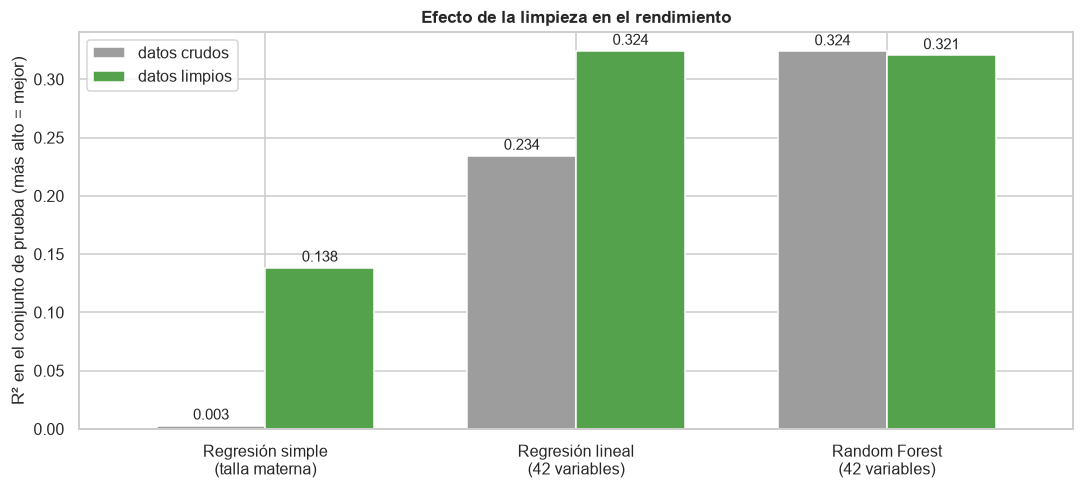

**Cómo leerlo:** R² es la proporción de la variación del puntaje Z que el modelo explica (0 = nada, 1 = todo). Cada par de barras es el mismo modelo con datos crudos (gris) y limpios (verde).  
**Qué vemos:** la mayor mejora es en la **regresión simple**, que pasa de 0.003 a 0.138: sin el código 9999 la talla de la madre por fin se ve como el buen predictor que es. La regresión lineal con 42 variables sube +0.090 (de 0.234 a 0.324) y **alcanza al Random Forest** (0.321). El Random Forest casi no cambia (0.324 → 0.321; RMSE 0.849 → 0.851) porque ya toleraba los códigos. **Conclusión:** la limpieza ayuda sobre todo a los modelos lineales; para XGBoost su valor está en la *claridad* y *confiabilidad* (ya no hay códigos que confundan la interpretación ni las importancias).

In [22]:
def evaluar(datos, feats, categ, mask_test):
    X, y = datos[feats], datos["haz"]
    Xtr, Xte, ytr, yte = X[~mask_test], X[mask_test], y[~mask_test], y[mask_test]
    num = [c for c in feats if c not in categ]
    prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                              ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))]), categ)])
    salida = {}
    s = Pipeline([("i", SimpleImputer(strategy="median")), ("m", LinearRegression())]).fit(Xtr[["talla_madre_x10"]], ytr)
    salida["Regresión simple\n(talla materna)"] = r2_score(yte, s.predict(Xte[["talla_madre_x10"]]))
    lr = Pipeline([("p", prep), ("m", LinearRegression())]).fit(Xtr, ytr)
    salida["Regresión lineal\n(42 variables)"] = r2_score(yte, lr.predict(Xte))
    rf = Pipeline([("p", prep), ("m", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))]).fit(Xtr, ytr)
    pred = rf.predict(Xte)
    salida["Random Forest\n(42 variables)"] = r2_score(yte, pred)
    return salida, float(np.sqrt(mean_squared_error(yte, pred)))


# crudo: mismos niños y misma partición
crudo_ok = crudo[crudo["haz"].notna()].reset_index(drop=True)
feats_crudo = dic.loc[dic.rol == "feature", "nombre"].tolist()
categ_crudo = dic.loc[(dic.rol == "feature") & (dic.tipo == "categórica"), "nombre"].tolist()
mask = (df["particion"] == "test").values
r_crudo, rmse_crudo = evaluar(crudo_ok, feats_crudo, categ_crudo, mask)
r_limpio, rmse_limpio = evaluar(df, FEATURES, CATEG, mask)

comp = pd.DataFrame({"datos crudos": r_crudo, "datos limpios": r_limpio})
fig, ax = plt.subplots(figsize=(10, 4.6))
comp.plot.bar(ax=ax, color=[GRIS, VERDE], rot=0, width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9.5, padding=2)
ax.set_ylabel("R² en el conjunto de prueba (más alto = mejor)")
ax.set_title("Efecto de la limpieza en el rendimiento")
ax.legend(title="")
plt.tight_layout()
plt.show()

mejora = comp["datos limpios"] - comp["datos crudos"]
mejora = comp["datos limpios"] - comp["datos crudos"]
sube_rf = "casi no cambia" if abs(mejora.iloc[2]) < 0.01 else ("mejora" if mejora.iloc[2] > 0 else "empeora")
nota(f"**Cómo leerlo:** R² es la proporción de la variación del puntaje Z que el modelo explica (0 = nada, 1 = todo). Cada par de barras es el mismo modelo con datos crudos (gris) y limpios (verde).  " + chr(10) +
     f"**Qué vemos:** la mayor mejora es en la **regresión simple**, que pasa de {comp.iloc[0, 0]:.3f} a {comp.iloc[0, 1]:.3f}: sin el código 9999 la talla de la madre por fin se ve como el buen predictor que es. "
     f"La regresión lineal con 42 variables sube {mejora.iloc[1]:+.3f} (de {comp.iloc[1, 0]:.3f} a {comp.iloc[1, 1]:.3f}) y **alcanza al Random Forest** ({comp.iloc[2, 1]:.3f}). "
     f"El Random Forest {sube_rf} ({comp.iloc[2, 0]:.3f} → {comp.iloc[2, 1]:.3f}; RMSE {rmse_crudo:.3f} → {rmse_limpio:.3f}) porque ya toleraba los códigos. "
     f"**Conclusión:** la limpieza ayuda sobre todo a los modelos lineales; para XGBoost su valor está en la *claridad* y *confiabilidad* (ya no hay códigos que confundan la interpretación ni las importancias).")

## Resumen
- **Entrada:** `dataset_integrado_crudo.csv` (18 841 niños, sin tocar). **Salida:** `dataset_limpio.csv` (con la columna `particion`), `diccionario_limpio.csv` y `registro_limpieza.csv`.
- **Qué se hizo:** se quitaron los niños sin objetivo; se convirtieron los códigos especiales en vacíos; se corrigieron las incoherencias; se decidió conservar los atípicos reales; las vacunas se interpretan según la edad; se codificaron binarias, ordinales y nominales; se dividió por conglomerado; imputación y escalado quedan para los *Pipelines* (solo *train*).
- **Siguiente:** notebook 04 (EDA con datos limpios) y luego el modelo XGBoost.